In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device: ", device)

Using device:  cuda


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/aorta589/Aorta 589.zip"
extract_path = "/content/drive/MyDrive/aorta589/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
  zip_ref.extractall(extract_path)

all_files = os.listdir(extract_path)
img_path = sorted([os.path.join(extract_path, f) for f in all_files if f.endswith(".jpg")])
mask_path = sorted([os.path.join(extract_path, f) for f in all_files if f.endswith(".png") or "AO" in f])

print("Found images: ", len(img_path))
print("Found masks: ", len(mask_path))

Found images:  589
Found masks:  589


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

test_transform = A.Compose([
    A.Resize(512, 512),
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    ToTensorV2()
])

class AortaTestDataset(Dataset):
    def __init__(self, img_paths, mask_paths, transform=None):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.img_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask > 128).astype(np.float32)

        if self.transform:
            transformed = self.transform(image=img, mask=mask)
            img = transformed['image']
            mask = transformed['mask']

        return img, mask, os.path.basename(self.img_paths[idx])

test_dataset = AortaTestDataset(img_path, mask_path, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

In [ ]:
!pip install segmentation-models-pytorch
import segmentation_models_pytorch as smp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.3 MB/s eta 0:00:00


In [ ]:
model = smp.Segformer(
    encoder_name = "resnet34",
    encoder_weights = "imagenet",
    in_channels = 3,
    classes = 1,
).to(device)

pth_path = "/content/drive/MyDrive/aorta589/model/best_segformer_model.pth"
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Segformer(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, 

In [ ]:
import torch
import numpy as np
import cv2
from scipy.ndimage import label, binary_fill_holes
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt

# -----------------------------
# Функции метрик
# -----------------------------

# Dice коэффициент
def dice_coef(pred, gt):
    pred = pred.flatten()
    gt = gt.flatten()
    return (2*(pred*gt).sum()) / (pred.sum() + gt.sum() + 1e-8)

def keep_largest_object(mask):
    labeled, n = label(mask)
    if n == 0:
        return np.zeros_like(mask)
    sizes = [np.sum(labeled==k) for k in range(1,n+1)]
    largest_label = np.argmax(sizes) + 1
    clean_mask = (labeled == largest_label).astype(np.uint8)
    return clean_mask

# Max Feret Diameter в мм
def max_feret_diameter(mask, spacing=(0.7,0.7)):
    mask = keep_largest_object(mask)
    mask = binary_fill_holes(mask).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) == 0:
        return 0
    contour = contours[0]
    points = contour.squeeze()
    if len(points.shape) != 2:
        return 0

    points_mm = np.zeros_like(points, dtype=np.float32)
    points_mm[:,0] = points[:,0]*spacing[1]
    points_mm[:,1] = points[:,1]*spacing[0]
    distances = pdist(points_mm)
    return distances.max()

# Equivalent Diameter в мм
def equivalent_diameter(mask, spacing=(0.7,0.7)):
    mask = keep_largest_object(mask)
    mask = binary_fill_holes(mask)
    pixel_area = spacing[0]*spacing[1]
    area_mm2 = mask.sum()*pixel_area
    return 2*np.sqrt(area_mm2/np.pi)


dice_scores = []
max_pred_list, max_gt_list = [], []
equiv_pred_list, equiv_gt_list = [], []

spacing = (0.7,0.7)

with torch.no_grad():
    for imgs, masks, names in test_loader:
        imgs = imgs.to(device).float()
        outputs = torch.sigmoid(model(imgs)) > 0.5

        preds = outputs.cpu().numpy().astype(np.uint8)
        masks_np = masks.cpu().numpy().astype(np.uint8)

        for i in range(len(imgs)):
            pred_mask = preds[i,0]
            gt_mask = masks_np[i]


            dice_scores.append(dice_coef(pred_mask, gt_mask))


            max_pred_list.append(max_feret_diameter(pred_mask, spacing))
            max_gt_list.append(max_feret_diameter(gt_mask, spacing))

            equiv_pred_list.append(equivalent_diameter(pred_mask, spacing))
            equiv_gt_list.append(equivalent_diameter(gt_mask, spacing))


max_diff = np.array(max_pred_list) - np.array(max_gt_list)
equiv_diff = np.array(equiv_pred_list) - np.array(equiv_gt_list)

print(f"Средний Dice: {np.mean(dice_scores):.4f}")
print(f"Средняя ошибка Max Feret: {np.mean(np.abs(max_diff)):.2f} мм")
print(f"Средняя ошибка Equivalent Diameter: {np.mean(np.abs(equiv_diff)):.2f} мм")



Средний Dice: 0.9641
Средняя ошибка Max Feret: 0.92 мм
Средняя ошибка Equivalent Diameter: 0.60 мм


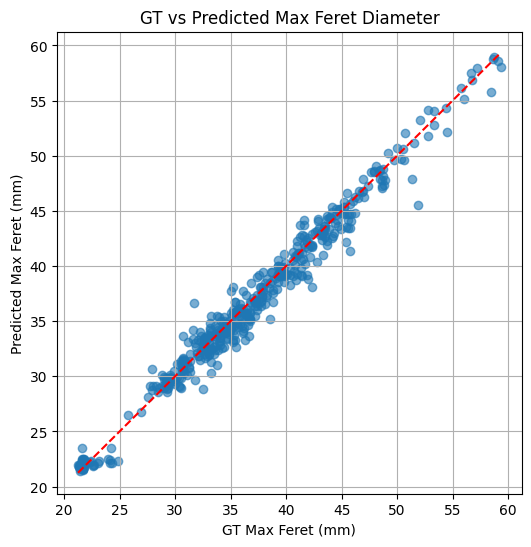

In [ ]:
import matplotlib.pyplot as plt

gt_feret = np.array(max_gt_list)
pred_feret = np.array(max_pred_list)

valid = gt_feret < 60
gt_feret = gt_feret[valid]
pred_feret = pred_feret[valid]

plt.figure(figsize=(6,6))
plt.scatter(gt_feret, pred_feret, alpha=0.6)
plt.plot([gt_feret.min(), gt_feret.max()],
         [gt_feret.min(), gt_feret.max()],
         'r--')

plt.xlabel("GT Max Feret (mm)")
plt.ylabel("Predicted Max Feret (mm)")
plt.title("GT vs Predicted Max Feret Diameter")
plt.grid(True)
plt.show()

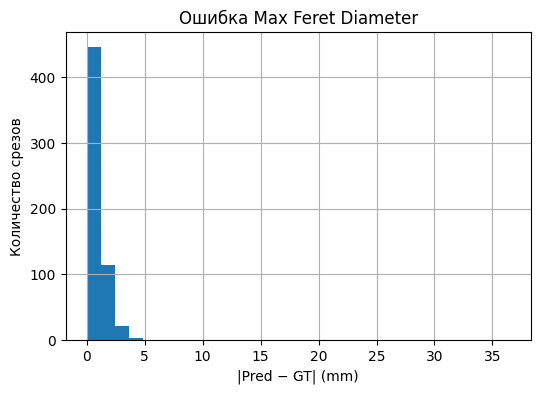

In [ ]:
diff_feret = np.abs(pred_feret - gt_feret)

plt.figure(figsize=(6,4))
plt.hist(diff_feret, bins=30)
plt.xlabel("|Pred − GT| (mm)")
plt.ylabel("Количество срезов")
plt.title("Ошибка Max Feret Diameter")
plt.grid(True)
plt.show()

In [ ]:
print(f"Mean error: {diff_feret.mean():.2f} mm")
print(f"Median error: {np.median(diff_feret):.2f} mm")

Mean error: 0.92 mm
Median error: 0.61 mm


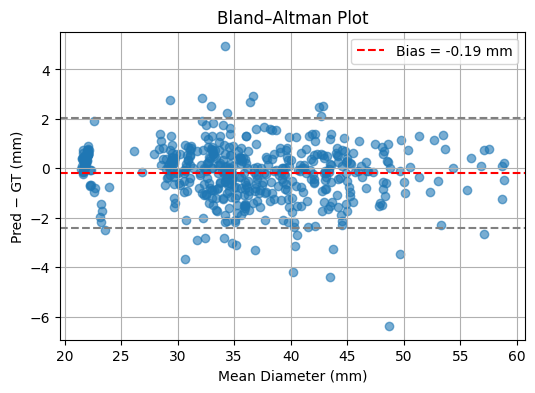

In [ ]:
mean_vals = (gt_feret + pred_feret) / 2
diff_vals = pred_feret - gt_feret

bias = diff_vals.mean()
std = diff_vals.std()

plt.figure(figsize=(6,4))
plt.scatter(mean_vals, diff_vals, alpha=0.6)
plt.axhline(bias, color='r', linestyle='--', label=f'Bias = {bias:.2f} mm')
plt.axhline(bias + 1.96*std, color='gray', linestyle='--')
plt.axhline(bias - 1.96*std, color='gray', linestyle='--')

plt.xlabel("Mean Diameter (mm)")
plt.ylabel("Pred − GT (mm)")
plt.title("Bland–Altman Plot")
plt.legend()
plt.grid(True)
plt.show()

Normal (<30 mm): mean error = 0.53 mm
Borderline (27–33 mm): mean error = 0.71 mm
Aneurysm (>30 mm): mean error = 0.90 mm


/tmp/ipython-input-3820160934.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(group_errors, labels=labels)


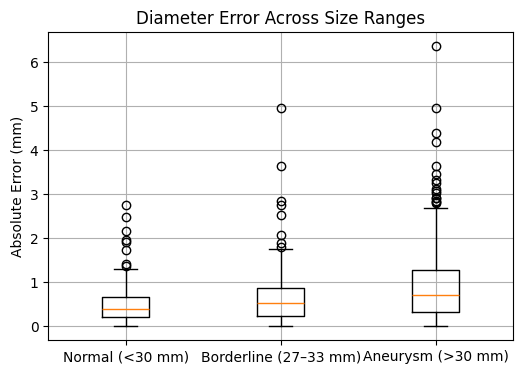

In [ ]:
groups = {
    "Normal (<30 mm)": gt_feret < 30,
    "Borderline (27–33 mm)": (gt_feret >= 27) & (gt_feret <= 33),
    "Aneurysm (>30 mm)": gt_feret > 30
}

group_errors = []

labels = []
for name, mask in groups.items():
    if mask.sum() > 0:
        err = np.abs(pred_feret[mask] - gt_feret[mask])
        group_errors.append(err)
        labels.append(name)
        print(f"{name}: mean error = {err.mean():.2f} mm")


plt.figure(figsize=(6,4))
plt.boxplot(group_errors, labels=labels)
plt.ylabel("Absolute Error (mm)")
plt.title("Diameter Error Across Size Ranges")
plt.grid(True)
plt.show()

In [ ]:
def classify(diameter_mm, threshold=30):
    return diameter_mm >= threshold


gt_class = classify(gt_feret)
pred_class = classify(pred_feret)


from sklearn.metrics import confusion_matrix

cm = confusion_matrix(gt_class, pred_class)
tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Accuracy: {accuracy:.3f}")
print(f"Sensitivity (Aneurysm): {sensitivity:.3f}")
print(f"Specificity (Normal): {specificity:.3f}")

Accuracy: 0.977
Sensitivity (Aneurysm): 0.980
Specificity (Normal): 0.962
